In [1]:
#Libraries
import numpy as np
import pandas as pd
import datetime as dt
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm

In [2]:
#Set time to extract historical data
#years = 15
endDate = dt.datetime(2023, 10, 31)
startDate = dt.datetime(2023, 10, 1)



In [3]:
#create a list for tickers
tickers = ['SPY', 'BND', 'GLD', 'QQQ', 'VTI']

In [4]:
#download adjusted close prices
adj_close_df = pd.DataFrame()
for ticker in tickers:
    data = yf.download(ticker, start = startDate, end = endDate, auto_adjust = False, progress = False)
    adj_close_df[ticker] = data['Adj Close'].squeeze()
print(adj_close_df)

                   SPY        BND         GLD         QQQ         VTI
Date                                                                 
2023-10-02  412.098694  61.438293  169.649994  355.204193  204.163574
2023-10-03  406.582214  60.940460  169.160004  348.970490  201.199265
2023-10-04  409.542938  61.340504  169.139999  353.719513  202.652512
2023-10-05  409.388611  61.384964  168.830002  352.677277  202.546631
2023-10-06  414.249176  61.144913  169.699997  358.586639  204.962402
2023-10-09  416.901367  61.767208  172.820007  360.415344  206.252075
2023-10-10  419.071289  61.704987  172.529999  362.411346  207.532135
2023-10-11  420.787933  61.989487  173.789993  364.997284  208.350220
2023-10-12  418.222626  61.456070  173.259995  363.728912  206.675537
2023-10-13  416.139435  61.740566  178.830002  359.156860  205.511002
2023-10-16  420.517853  61.420540  177.960007  363.217560  207.897842
2023-10-17  420.498566  61.020473  178.289993  362.027924  208.167328
2023-10-18  414.8953

In [5]:
#calculate daily log returns and drop na
log_returns = np.log(adj_close_df/adj_close_df.shift(1))
log_returns = log_returns.dropna()
print(log_returns)

                 SPY       BND       GLD       QQQ       VTI
Date                                                        
2023-10-03 -0.013477 -0.008136 -0.002892 -0.017705 -0.014626
2023-10-04  0.007256  0.006543 -0.000118  0.013517  0.007197
2023-10-05 -0.000377  0.000725 -0.001834 -0.002951 -0.000523
2023-10-06  0.011803 -0.003918  0.005140  0.016617  0.011856
2023-10-09  0.006382  0.010126  0.018218  0.005087  0.006273
2023-10-10  0.005191 -0.001008 -0.001680  0.005523  0.006187
2023-10-11  0.004088  0.004600  0.007277  0.007110  0.003934
2023-10-12 -0.006115 -0.008642 -0.003054 -0.003481 -0.008070
2023-10-13 -0.004994  0.004619  0.031642 -0.012650 -0.005651
2023-10-16  0.010467 -0.005197 -0.004877  0.011243  0.011547
2023-10-17 -0.000046 -0.006535  0.001853 -0.003281  0.001295
2023-10-18 -0.013415 -0.004380  0.014367 -0.013205 -0.014905
2023-10-19 -0.008825 -0.004399  0.012199 -0.009401 -0.009477
2023-10-20 -0.012364  0.003668  0.002727 -0.015030 -0.012442
2023-10-23 -0.001735  0.

In [6]:
#Create equally weighted portfolio
portfolio_value = 1000000
weights = np.array([1/len(tickers)]*len(tickers))
print(weights)

[0.2 0.2 0.2 0.2 0.2]


In [7]:
#calculate historical porfolio return
historical_returns = (log_returns*weights).sum(axis=1)
print(historical_returns)

Date
2023-10-03   -0.011367
2023-10-04    0.006879
2023-10-05   -0.000992
2023-10-06    0.008300
2023-10-09    0.009217
2023-10-10    0.002843
2023-10-11    0.005402
2023-10-12   -0.005873
2023-10-13    0.002593
2023-10-16    0.004637
2023-10-17   -0.001343
2023-10-18   -0.006308
2023-10-19   -0.003981
2023-10-20   -0.006688
2023-10-23   -0.000208
2023-10-24    0.005591
2023-10-25   -0.011517
2023-10-26   -0.006686
2023-10-27    0.001282
2023-10-30    0.005282
dtype: float64


In [8]:
#find x day historical retuns i.e. rolling averages
days = 1

range_returns = historical_returns.rolling(window = days).sum()
range_returns = range_returns.dropna()
print(range_returns)

Date
2023-10-03   -0.011367
2023-10-04    0.006879
2023-10-05   -0.000992
2023-10-06    0.008300
2023-10-09    0.009217
2023-10-10    0.002843
2023-10-11    0.005402
2023-10-12   -0.005873
2023-10-13    0.002593
2023-10-16    0.004637
2023-10-17   -0.001343
2023-10-18   -0.006308
2023-10-19   -0.003981
2023-10-20   -0.006688
2023-10-23   -0.000208
2023-10-24    0.005591
2023-10-25   -0.011517
2023-10-26   -0.006686
2023-10-27    0.001282
2023-10-30    0.005282
dtype: float64


In [9]:
#specify confidence interval and calculate VaR
confidence_interval = 0.99

VaR = -np.percentile(range_returns, 100 - (confidence_interval * 100))*portfolio_value
print(VaR)

11488.334746248422


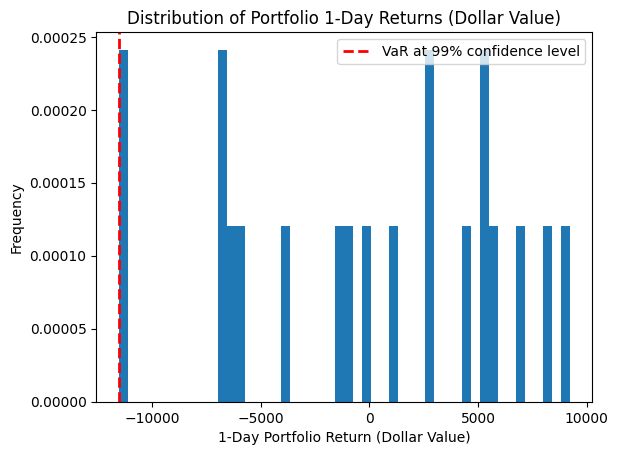

In [10]:
return_window = days
range_returns = historical_returns.rolling(window=return_window).sum()
range_returns = range_returns.dropna()

range_returns_dollar = range_returns * portfolio_value

plt.hist(range_returns_dollar.dropna(), bins=50, density=True)
plt.xlabel(f'{return_window}-Day Portfolio Return (Dollar Value)')
plt.ylabel('Frequency')
plt.title(f'Distribution of Portfolio {return_window}-Day Returns (Dollar Value)')
plt.axvline(-VaR, color='r', linestyle='dashed', linewidth=2, label=f'VaR at {confidence_interval:.0%} confidence level')
plt.legend()
plt.show()

## Out-of-sample backtest: all three methods on October 2023
Estimate 1-day VaR and ES with each method from the 15 years to 30 September 2023, then test them on every trading day of October 2023:
- **Exceedances:** days when the portfolio loss was bigger than VaR (expected: about 5% of days at 95%, 1% at 99%).
- **ES check:** on exceedance days, the average actual loss compared with the ES forecast.

One month is a small sample (about 21 days), so this is a sense check rather than a formal test.

In [11]:
# Estimation window: 15 years to 30 September 2023
est_end = dt.datetime(2023, 9, 30)
est_start = est_end - dt.timedelta(days = 365*15)
est_prices = pd.DataFrame()
for ticker in tickers:
    data = yf.download(ticker, start = est_start, end = est_end, auto_adjust = False, progress = False)
    est_prices[ticker] = data['Adj Close'].squeeze()
est_returns = (np.log(est_prices / est_prices.shift(1)).dropna() * weights).sum(axis=1)

# Test window: every trading day of October 2023
test_prices = pd.DataFrame()
for ticker in tickers:
    data = yf.download(ticker, start = dt.datetime(2023, 9, 29), end = dt.datetime(2023, 11, 1), auto_adjust = False, progress = False)
    test_prices[ticker] = data['Adj Close'].squeeze()
test_returns = (np.log(test_prices / test_prices.shift(1)).dropna() * weights).sum(axis=1)
print(len(est_returns), 'estimation days;', len(test_returns), 'test days')

3772 estimation days; 22 test days


In [12]:
np.random.seed(42)
mu, sigma = est_returns.mean(), est_returns.std()
sims = np.random.normal(mu, sigma, 100000)

def var_es(cl):
    out = {}
    cut = np.percentile(est_returns, 100 * (1 - cl))
    out['Historical'] = (-cut, -est_returns[est_returns <= cut].mean())
    z = norm.ppf(1 - cl)
    out['Parametric'] = (-(mu + sigma * z), -(mu - sigma * norm.pdf(z) / (1 - cl)))
    cut = np.percentile(sims, 100 * (1 - cl))
    out['Monte Carlo'] = (-cut, -sims[sims <= cut].mean())
    return out

rows = []
for cl in [0.95, 0.99]:
    for method, (v, e) in var_es(cl).items():
        hits = test_returns[-test_returns > v]
        rows.append({'Confidence': f'{cl:.0%}', 'Method': method,
                     '1-day VaR ($)': round(v * portfolio_value), '1-day ES ($)': round(e * portfolio_value),
                     'Exceedances': len(hits), 'Expected': round((1 - cl) * len(test_returns), 2),
                     'Avg loss on exceedance days ($)': round(-hits.mean() * portfolio_value) if len(hits) else None})
backtest = pd.DataFrame(rows)
backtest

,Confidence,Method,1-day VaR ($),1-day ES ($),Exceedances,Expected,Avg loss on exceedance days ($)
0,95%,Historical,12216,20178,0,1.10,None
1,95%,Parametric,13302,16772,0,1.10,None
2,95%,Monte Carlo,13290,16790,0,1.10,None
3,99%,Historical,24306,34787,0,0.22,None
4,99%,Parametric,18962,21776,0,0.22,None
5,99%,Monte Carlo,19031,21820,0,0.22,None


Worst day in October 2023: 2023-10-25, loss $11,517


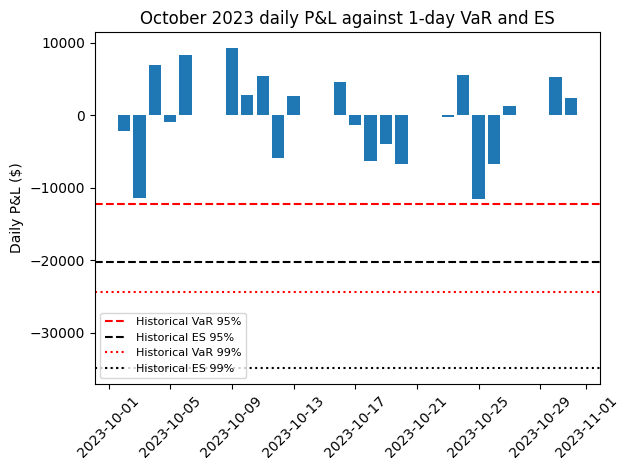

In [13]:
worst = -test_returns.min() * portfolio_value
print(f'Worst day in October 2023: {test_returns.idxmin().date()}, loss ${worst:,.0f}')
plt.bar(test_returns.index, test_returns * portfolio_value)
for cl, ls in [(0.95, '--'), (0.99, ':')]:
    for method, (v, e) in var_es(cl).items():
        if method == 'Historical':
            plt.axhline(-v * portfolio_value, linestyle=ls, color='r', label=f'Historical VaR {cl:.0%}')
            plt.axhline(-e * portfolio_value, linestyle=ls, color='k', label=f'Historical ES {cl:.0%}')
plt.ylabel('Daily P&L ($)')
plt.title('October 2023 daily P&L against 1-day VaR and ES')
plt.legend(fontsize=8)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()